# Week 7 — Seoul Bike Sharing: AI-Enhanced Digital Twin (Team B)

**Goal:** Extend the Week 5 calibrated model and the Week 6 context-based workflow with machine learning, and test whether AI improves predictions on **unseen, later** observations.

| Task | Model | Equation |
|---|---|---|
| **B1** | Direct AI demand model (Random Forest) | `D_AI(t) = f_AI(weather(t), calendar(t))` |
| **B2** | One-hour-ahead AI forecast (Random Forest) | `D_forecast(t+1) = g_AI(D(t), D(t−1), X(t))` |
| **B3** | Hybrid model: Week 5 baseline + AI residual correction | `D_hybrid(t) = D_base(t) + r_AI(t)` |

**Test period:** 15–28 October 2018 (the same period as the Week 6 context-based estimate), so all methods can be compared directly. All models are trained **only on earlier hours**. There is no random shuffling.

**What each model is allowed to see:**

| Model | Past rentals | Weather | Calendar of target hour |
|---|---|---|---|
| Week 6 rule-based | historical reference hours only | target-hour temperature (matching) | ✓ |
| Week 5 linear | `D(t)` | target-hour `T(t+1)`, `H(t+1)` (perfect-forecast assumption from Week 5) | hour |
| B1 direct AI | ✗ none | target-hour weather (same assumption as Week 5) | ✓ |
| B2 forecast AI | `D(t)`, `D(t−1)` | **current** weather `X(t)` only — no future weather | ✓ |
| B3 hybrid | `D(t)`, `D(t−1)` | same inputs as Week 5 baseline | ✓ |

The calendar of the next hour (hour of day, weekday, holiday) is known in advance, so it is a valid input. Observed future rentals are **never** used as inputs.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

TEST_START = pd.Timestamp('2018-10-15 00:00')
TEST_END = pd.Timestamp('2018-10-28 23:00')

# Week 6 rule-based settings (same values as the Week 6 notebook)
HOUR_TOLERANCE = 1
TEMPERATURE_TOLERANCE = 3.0
MIN_MATCHES = 1

# Random Forest settings (fixed before looking at the test period)
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)

# B3: share of the training period used to fit the baseline (rest: residual model)
BASE_FIT_SHARE = 0.7

## 2. Load and prepare the Seoul observations

Same checks as in Weeks 5–6: timestamps from `Date` + `Hour` (Seoul local time), missing values, duplicates and invalid values. Calendar context is derived from the timestamp and the existing `Holiday` column.

In [2]:
csv_path = next(p for p in [Path('../SeoulBikeData.csv'), Path('SeoulBikeData.csv')] if p.exists())
df = pd.read_csv(csv_path, encoding='latin1')
df['Timestamp'] = pd.to_datetime(df['Date'], dayfirst=True) + pd.to_timedelta(df['Hour'], unit='h')

print('Rows:', len(df))
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate timestamps:', int(df['Timestamp'].duplicated().sum()))

df = df.dropna().drop_duplicates('Timestamp').sort_values('Timestamp').reset_index(drop=True)
df = df[(df['Rented Bike Count'] >= 0) & df['Humidity(%)'].between(0, 100)].copy()

df['Operating'] = df['Functioning Day'].eq('Yes')
df['Weekday'] = df['Timestamp'].dt.weekday            # 0 = Monday ... 6 = Sunday
df['Day type'] = np.where(df['Weekday'] >= 5, 'weekend', 'weekday')
df['Is weekend'] = (df['Weekday'] >= 5).astype(int)
df['Is holiday'] = df['Holiday'].eq('Holiday').astype(int)
df['Month'] = df['Timestamp'].dt.month

print('Clean rows:', len(df), '| Period:', df.Timestamp.min(), 'to', df.Timestamp.max())

Rows: 8760
Missing values: 0
Duplicate timestamps: 0
Clean rows: 8760 | Period: 2017-12-01 00:00:00 to 2018-11-30 23:00:00


## 3. Build one dataset row per target hour

Each row describes a **target hour** (the hour we want to predict) together with information that is available one hour earlier:

- `D_t`, `D_t1`: observed rentals in the previous hour and two hours before.
- `T_now`, `H_now`, `Rain_now`, `Wind_now`: weather observed in the previous hour (known at forecast time).
- `T_next`, `H_next`, `Rain_next`, `Wind_next`: weather of the target hour (used only by models with the perfect-forecast assumption).

Rows are kept only if the three hours are consecutive and the service was operating in all of them (a zero during a shutdown is not zero demand).

In [3]:
prev1 = df.shift(1)
prev2 = df.shift(2)

data = pd.DataFrame({
    'Timestamp': df['Timestamp'],
    'Hour': df['Hour'],
    'Weekday': df['Weekday'],
    'Is weekend': df['Is weekend'],
    'Is holiday': df['Is holiday'],
    'Month': df['Month'],
    'Seasons': df['Seasons'],
    'Day type': df['Day type'],
    'D_t': prev1['Rented Bike Count'],
    'D_t1': prev2['Rented Bike Count'],
    'T_now': prev1['Temperature(°C)'],
    'H_now': prev1['Humidity(%)'],
    'Rain_now': prev1['Rainfall(mm)'],
    'Wind_now': prev1['Wind speed (m/s)'],
    'T_next': df['Temperature(°C)'],
    'H_next': df['Humidity(%)'],
    'Rain_next': df['Rainfall(mm)'],
    'Wind_next': df['Wind speed (m/s)'],
    'Observed': df['Rented Bike Count'].astype(float),
})

consecutive = (df['Timestamp'] - prev1['Timestamp'] == pd.Timedelta(hours=1)) & \
              (prev1['Timestamp'] - prev2['Timestamp'] == pd.Timedelta(hours=1))
operating = df['Operating'] & prev1['Operating'].eq(True) & prev2['Operating'].eq(True)
data = data[consecutive & operating].dropna().reset_index(drop=True)

train = data[data['Timestamp'] < TEST_START].copy()
test = data[data['Timestamp'].between(TEST_START, TEST_END)].copy()
assert train['Timestamp'].max() < test['Timestamp'].min()

print('Training hours:', len(train), '|', train.Timestamp.min(), '->', train.Timestamp.max())
print('Test hours:    ', len(test), '|', test.Timestamp.min(), '->', test.Timestamp.max())

Training hours: 7389 | 2017-12-01 02:00:00 -> 2018-10-14 23:00:00
Test hours:     336 | 2018-10-15 00:00:00 -> 2018-10-28 23:00:00


## 4. Metrics and helper functions

- **MAE**: average absolute error (bicycles/hour).
- **RMSE**: like MAE, but large errors count more (bicycles/hour).
- **R²**: share of the variation explained (1 = perfect, 0 = no better than the test mean).

Predictions are clipped at zero only for reporting, because rentals cannot be negative.

In [4]:
def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def r2(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))

def scores(y, p):
    return {'MAE': mae(y, p), 'RMSE': rmse(y, p), 'R²': r2(y, p)}

def plot_test(columns, title):
    # One continuous hourly index so missing hours appear as gaps, not lines
    chart = test.set_index('Timestamp')[['Observed'] + columns].asfreq('h')
    plt.figure(figsize=(13, 5))
    plt.plot(chart.index, chart['Observed'], label='Observed', color='black', linewidth=2)
    for column in columns:
        plt.plot(chart.index, chart[column], label=column, alpha=0.85)
    plt.title(title)
    plt.xlabel('Time (Seoul)')
    plt.ylabel('Bicycle rentals / hour')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

## 5. Baselines from earlier weeks

### 5.1 Week 5 calibrated linear model

`D(t+1) = b0 + b1·D(t) + b2·T(t+1) + b3·H(t+1) + g(hour)`, calibrated by least squares on the training hours only (same equation as Week 5, refitted on all hours before the test period, as in Week 6).

In [5]:
def week5_matrix(d):
    return np.column_stack(
        [np.ones(len(d)), d['D_t'], d['T_next'], d['H_next']]
        + [(d['Hour'] == h).astype(float) for h in range(1, 24)]
    )

b_week5, *_ = np.linalg.lstsq(week5_matrix(train), train['Observed'], rcond=None)
test['Week 5 linear'] = np.maximum(0, week5_matrix(test) @ b_week5)

print('Week 5 coefficients b0–b3:', np.round(b_week5[:4], 3))
print('Week 5 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['Week 5 linear']).items()})

Week 5 coefficients b0–b3: [-23.448   0.87    4.178  -1.114]
Week 5 test scores: {'MAE': 147.44, 'RMSE': 217.42, 'R²': 0.87}


### 5.2 Week 6 context-based (rule-based) estimate

Same transparent rules as Week 6: for each test hour, take all **earlier** operating hours with the same season, the same day type (weekday/weekend), the same holiday status, an hour of day within ±1 hour and a temperature within ±3 °C. The estimate is the **median** of their rentals. No past rentals of the test day are used. Hours without any match stay empty (`NaN`) — they are not filled.

In [6]:
history = df[df['Operating'] & (df['Timestamp'] < TEST_START)]

def rule_based(target):
    hour_diff = (history['Hour'] - target['Hour']).abs()
    hour_diff = np.minimum(hour_diff, 24 - hour_diff)
    matches = history[
        (history['Seasons'] == target['Seasons'])
        & (history['Day type'] == target['Day type'])
        & (history['Is holiday'] == target['Is holiday'])
        & (hour_diff <= HOUR_TOLERANCE)
        & ((history['Temperature(°C)'] - target['T_next']).abs() <= TEMPERATURE_TOLERANCE)
    ]
    return matches['Rented Bike Count'].median() if len(matches) >= MIN_MATCHES else np.nan

test['Rule-based (Week 6)'] = test.apply(rule_based, axis=1)
covered = test['Rule-based (Week 6)'].notna()
print(f'Rule-based coverage: {covered.sum()} / {len(test)} test hours')
print('Rule-based scores (covered hours):',
      {k: round(v, 2) for k, v in scores(test.loc[covered, 'Observed'], test.loc[covered, 'Rule-based (Week 6)']).items()})

Rule-based coverage: 312 / 336 test hours
Rule-based scores (covered hours): {'MAE': 186.21, 'RMSE': 304.37, 'R²': 0.75}


## 6. B1 — Learn demand patterns (direct AI)

A Random Forest learns rentals directly from **weather and calendar** variables of the target hour. It receives **no past rentals**, so it describes typical demand under given conditions (like the Week 6 rules, but learned from data).

**Features:**

| Feature | Meaning | Unit |
|---|---|---|
| `Hour` | hour of day | 0–23 |
| `Weekday` | day of week | 0 = Monday … 6 = Sunday |
| `Is weekend` | Saturday or Sunday | 0/1 |
| `Is holiday` | public holiday | 0/1 |
| `Month` | calendar month (season) | 1–12 |
| `T_next` | temperature | °C |
| `H_next` | relative humidity | % |
| `Rain_next` | rainfall | mm |
| `Wind_next` | wind speed | m/s |

Weather of the target hour is treated as a perfect forecast, the same assumption as the Week 5 model.

B1 test scores: {'MAE': 133.82, 'RMSE': 205.31, 'R²': 0.88}
Week 5 test scores: {'MAE': 147.44, 'RMSE': 217.42, 'R²': 0.87}


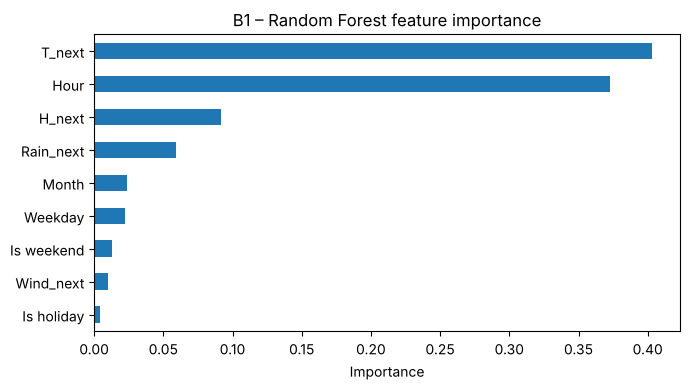

In [7]:
B1_FEATURES = ['Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month',
               'T_next', 'H_next', 'Rain_next', 'Wind_next']

model_b1 = RandomForestRegressor(**RF_PARAMS).fit(train[B1_FEATURES], train['Observed'])
test['B1 direct AI'] = np.maximum(0, model_b1.predict(test[B1_FEATURES]))

print('B1 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['B1 direct AI']).items()})
print('Week 5 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['Week 5 linear']).items()})

importance = pd.Series(model_b1.feature_importances_, index=B1_FEATURES).sort_values()
importance.plot(kind='barh', figsize=(7, 4), title='B1 – Random Forest feature importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

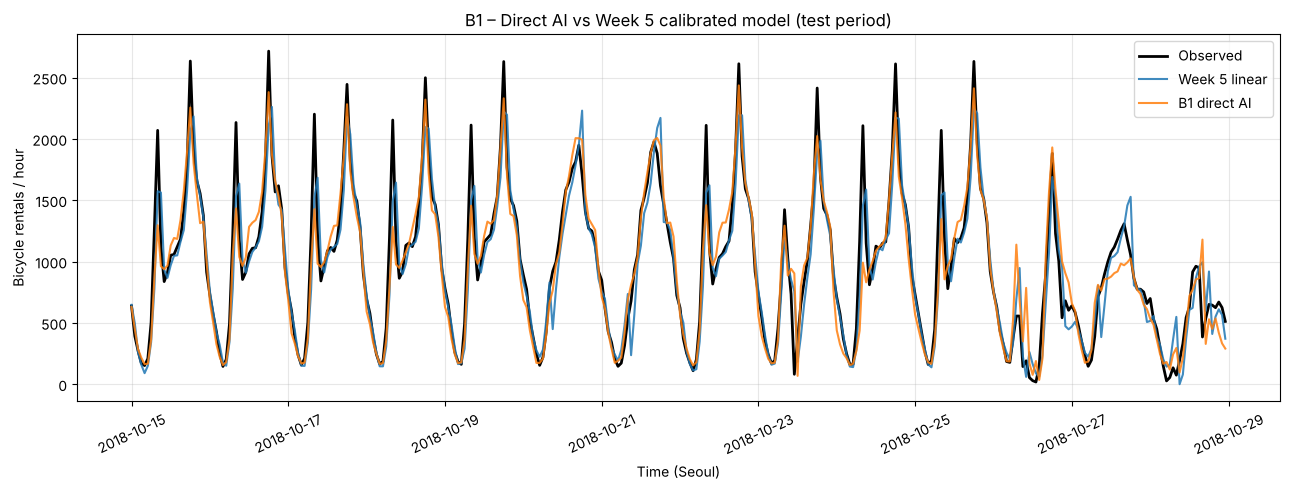

In [8]:
plot_test(['Week 5 linear', 'B1 direct AI'], 'B1 – Direct AI vs Week 5 calibrated model (test period)')

## 7. B2 — One-hour-ahead forecast

`D_forecast(t+1) = g_AI(D(t), D(t−1), X(t))`

At forecast time `t` we know the current and previous rentals, the **current** weather and the calendar of the next hour. Future observed weather and rentals are **not** used. This is a stricter (more realistic) setting than the Week 5 model, which used the observed weather of `t+1`.

In [9]:
B2_FEATURES = ['D_t', 'D_t1', 'T_now', 'H_now', 'Rain_now', 'Wind_now',
               'Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month']

# Safety check: no target-hour weather or target rentals in the inputs
assert not set(B2_FEATURES) & {'Observed', 'T_next', 'H_next', 'Rain_next', 'Wind_next'}

model_b2 = RandomForestRegressor(**RF_PARAMS).fit(train[B2_FEATURES], train['Observed'])
test['B2 forecast AI'] = np.maximum(0, model_b2.predict(test[B2_FEATURES]))

print('B2 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['B2 forecast AI']).items()})
print('Rule-based (covered hours):',
      {k: round(v, 2) for k, v in scores(test.loc[covered, 'Observed'], test.loc[covered, 'Rule-based (Week 6)']).items()})

B2 test scores: {'MAE': 70.38, 'RMSE': 107.76, 'R²': 0.97}
Rule-based (covered hours): {'MAE': 186.21, 'RMSE': 304.37, 'R²': 0.75}


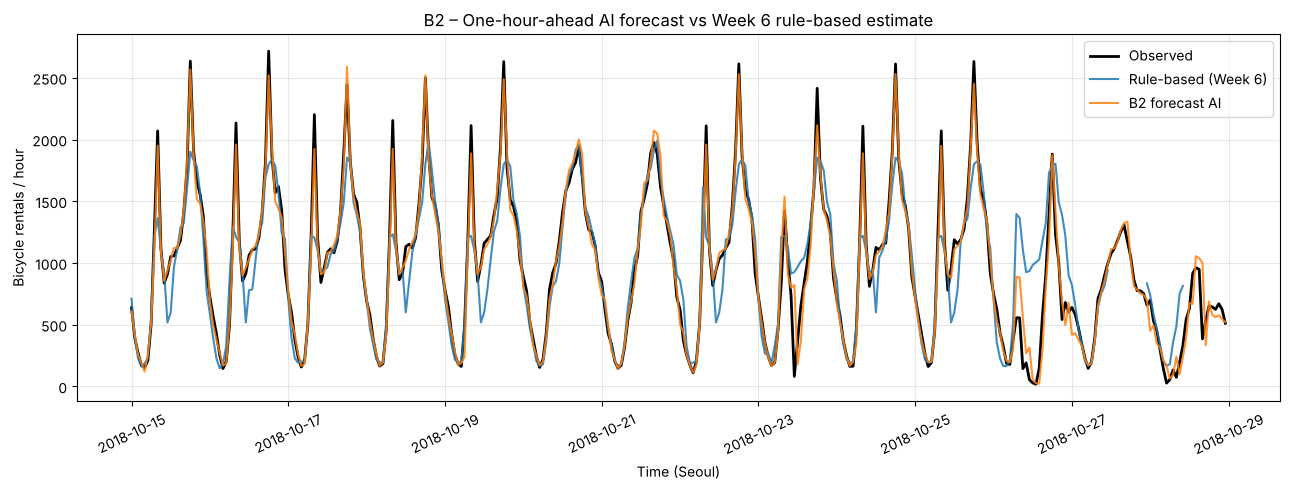

In [10]:
plot_test(['Rule-based (Week 6)', 'B2 forecast AI'], 'B2 – One-hour-ahead AI forecast vs Week 6 rule-based estimate')

## 8. B3 — Hybrid model: baseline + AI residual correction

`D_hybrid(t) = D_base(t) + r_AI(t)`, with `D_base` = the Week 5 calibrated linear model.

1. Split the training period in time: the first 70% (**part A**) and the last 30% (**part B**).
2. Calibrate the Week 5 baseline on part A only.
3. Compute its residuals on part B: `r(t) = D_observed(t) − D_base(t)`. These are **out-of-sample** errors, like the errors the baseline will make on the test period. (Residuals on the same data used for fitting would be too small and too optimistic.)
4. Train a Random Forest to predict `r(t)` from information available at prediction time.
5. On the test period: `D_hybrid = D_base + r_AI`.

In [11]:
cut = train['Timestamp'].iloc[int(len(train) * BASE_FIT_SHARE)]
part_a = train[train['Timestamp'] < cut]
part_b = train[train['Timestamp'] >= cut].copy()
print('Part A (baseline fit):', part_a.Timestamp.min(), '->', part_a.Timestamp.max(), f'({len(part_a)} h)')
print('Part B (residual fit):', part_b.Timestamp.min(), '->', part_b.Timestamp.max(), f'({len(part_b)} h)')

b_base, *_ = np.linalg.lstsq(week5_matrix(part_a), part_a['Observed'], rcond=None)
part_b['Residual'] = part_b['Observed'] - week5_matrix(part_b) @ b_base

B3_FEATURES = ['D_t', 'D_t1', 'T_next', 'H_next', 'Rain_next', 'Wind_next',
               'Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month']
model_b3 = RandomForestRegressor(**RF_PARAMS).fit(part_b[B3_FEATURES], part_b['Residual'])

test['Hybrid baseline only'] = np.maximum(0, week5_matrix(test) @ b_base)
test['AI correction'] = model_b3.predict(test[B3_FEATURES])
test['B3 hybrid'] = np.maximum(0, week5_matrix(test) @ b_base + test['AI correction'])

print('Mean residual of the baseline on part B:', round(part_b['Residual'].mean(), 1))
print('Baseline only (part-A fit):', {k: round(v, 2) for k, v in scores(test['Observed'], test['Hybrid baseline only']).items()})
print('B3 hybrid:                 ', {k: round(v, 2) for k, v in scores(test['Observed'], test['B3 hybrid']).items()})

Part A (baseline fit): 2017-12-01 02:00:00 -> 2018-07-06 17:00:00 (5172 h)
Part B (residual fit): 2018-07-06 18:00:00 -> 2018-10-14 23:00:00 (2217 h)


Mean residual of the baseline on part B: -32.8
Baseline only (part-A fit): {'MAE': 153.37, 'RMSE': 226.26, 'R²': 0.86}
B3 hybrid:                  {'MAE': 74.02, 'RMSE': 119.56, 'R²': 0.96}


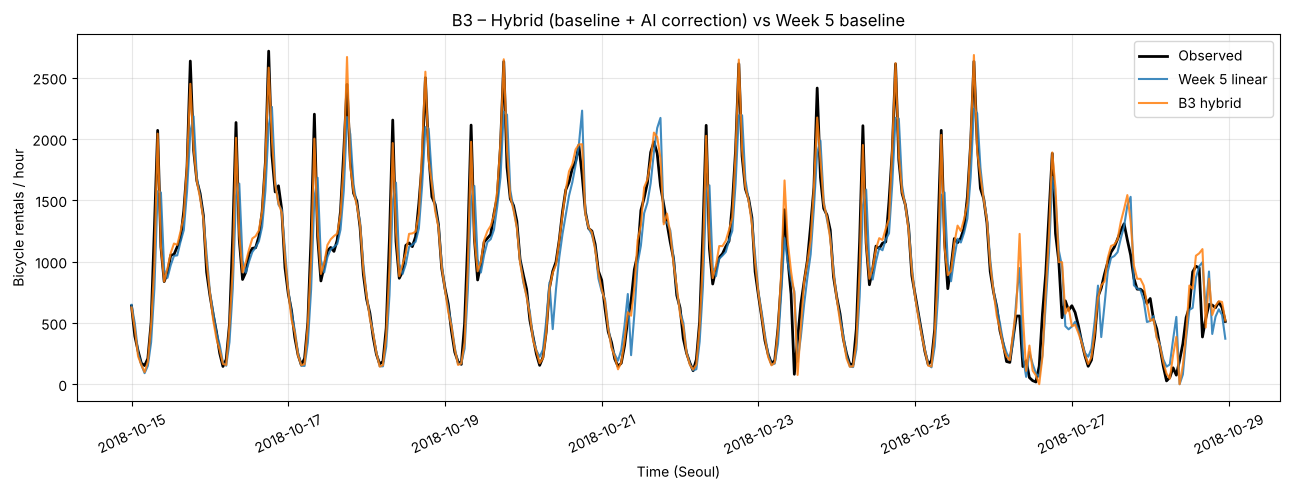

In [12]:
plot_test(['Week 5 linear', 'B3 hybrid'], 'B3 – Hybrid (baseline + AI correction) vs Week 5 baseline')

## 9. Comparison of all models on the same test period

Two tables:

1. **All test hours** — every model except the rule-based method has a prediction for every hour.
2. **Common hours** — only hours where the rule-based method found matches, so all five methods are compared on exactly the same timestamps.

In [13]:
MODELS = ['Rule-based (Week 6)', 'Week 5 linear', 'B1 direct AI', 'B3 hybrid', 'B2 forecast AI']

def comparison(rows):
    table = {}
    for m in MODELS:
        ok = rows[m].notna()
        table[m] = {'Hours': int(ok.sum()), **scores(rows.loc[ok, 'Observed'], rows.loc[ok, m])}
    return pd.DataFrame(table).T

print('All test hours (rule-based only on covered hours):')
print(comparison(test).round(2).to_string())
print('\nCommon hours (all five methods available):')
common = comparison(test[covered])
print(common.round(2).to_string())

All test hours (rule-based only on covered hours):
                     Hours     MAE    RMSE    R²
Rule-based (Week 6)  312.0  186.21  304.37  0.75
Week 5 linear        336.0  147.44  217.42  0.87
B1 direct AI         336.0  133.82  205.31  0.88
B3 hybrid            336.0   74.02  119.56  0.96
B2 forecast AI       336.0   70.38  107.76  0.97

Common hours (all five methods available):
                     Hours     MAE    RMSE    R²
Rule-based (Week 6)  312.0  186.21  304.37  0.75
Week 5 linear        312.0  148.18  218.44  0.87
B1 direct AI         312.0  130.25  202.47  0.89
B3 hybrid            312.0   69.99  111.57  0.97
B2 forecast AI       312.0   68.93  103.18  0.97


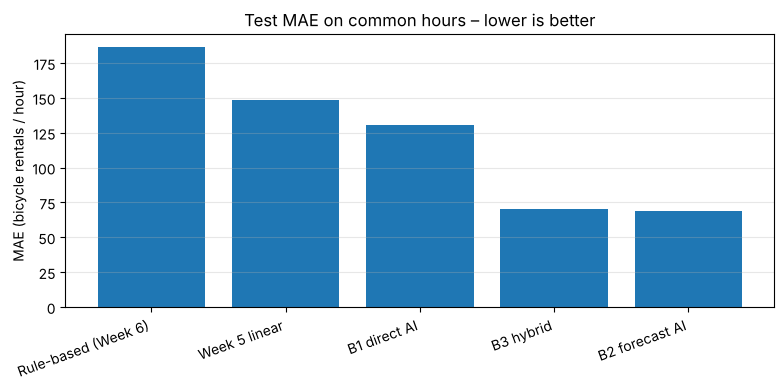

In [14]:
plt.figure(figsize=(8, 4))
plt.bar(common.index, common['MAE'])
plt.ylabel('MAE (bicycle rentals / hour)')
plt.title('Test MAE on common hours – lower is better')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Discussion

**Results (test period 15–28 Oct 2018, 312 common hours, MAE in bicycles/hour):**

| Model | MAE | Uses past rentals of the test day? |
|---|---|---|
| Rule-based (Week 6) | ≈186 | no |
| Week 5 linear | ≈148 | yes, `D(t)` |
| B1 direct AI | ≈130 | no |
| B3 hybrid | ≈70 | yes |
| B2 forecast AI | ≈69 | yes, `D(t)`, `D(t−1)` |

*(Exact values are printed in Section 9.)*

**B1 – Does AI learn demand patterns better?** Yes. The Random Forest has a lower error than the Week 5 linear model, although it sees **no past rentals**. It learns non-linear interactions (for example the morning peak exists on weekdays but not at weekends), which the linear model with a fixed hour effect cannot represent. It is also clearly better than the Week 6 rule-based estimate, which uses similar information but fixed matching rules. The most important features are hour of day and temperature.

**B2 – One-hour-ahead forecast.** The AI forecast more than halves the error of the Week 6 rule-based estimate and of the Week 5 model, even though it uses only the **current** weather (no future weather). The main reason is the recent rental history: `D(t)` and `D(t−1)` show the current level of demand, and the model learns how this level changes to the next hour depending on hour of day and day type.

**B3 – Does the AI correction help?** Yes. The baseline alone (fitted on part A) has an MAE of about 153; with the learned residual correction the hybrid reaches about 74 — roughly a 50% reduction. The baseline's residuals are systematic (they depend on hour, day type and season), so they are learnable. The hybrid keeps the interpretable Week 5 equation (`b0–b3`) and adds a data-driven correction, which is the hybrid physics/rule + AI idea of the course.

**Hybrid vs. pure AI.** B2 and B3 reach a similar accuracy. B3 has the advantage that its structure is explainable (coefficients with units plus a correction), while B2 is a black box. B3 still uses the perfect-forecast weather assumption of Week 5; B2 does not.

**Limitations:**
- The test period is only two weeks (336 hours) in autumn. Results may differ in other seasons; a longer or rolling evaluation would be more reliable.
- The weather of the target hour is a perfect-forecast assumption for the Week 5, B1 and B3 models. In real operation a weather forecast would add error.
- Random Forest settings were fixed in advance and not tuned; tuning on a validation period could improve the models further.
- Rentals are a proxy for demand. Shutdown hours are excluded, and supply limits (no bikes at a station) are not visible in city-level totals.
- AI predictions are estimates, not observations. They must not be used as ground truth.